# ERA V5 — Session 12 · ZeRO on 32 Virtual GPUs

**Assignment:** build 32 virtual GPUs, run a demo model on them, simulate
ZeRO-1/2/3, show how memory and computation change.

My first instinct was a memory calculator — implement the paper's formulas,
print a table, done. I rejected that, because a table of formulas proves
nothing about whether I understand what they describe. I could produce exactly
the right numbers with a completely wrong mental model of what reduce-scatter
does.

So I set one rule: **each virtual GPU may only touch bytes it actually owns.**
Under ZeRO-3 a rank holds 1/32nd of the parameters and genuinely cannot run a
forward pass until an all-gather hands it the rest. That constraint is what
makes this simulation capable of being *wrong*, and therefore worth running.

It buys one very strong test, which became the backbone of everything:

> If sharding is right, **the stage is invisible to the mathematics.** All four
> stages must walk identical optimization trajectories.

No PyTorch — pure NumPy with a hand-written autodiff tape. If I had imported
`deepspeed` and printed `max_memory_allocated()`, I'd have demonstrated that
DeepSpeed works, not that I understand why.

In [1]:
import json, numpy as np
import matplotlib.pyplot as plt
from zerosim import plots
from zerosim.device import Cluster
from zerosim.engine import ZeROEngine
from zerosim.fabric import Fabric, H100, B200
from zerosim.model import ModelConfig, total_params
from zerosim.memory_model import model_state_gb, model_state_bytes, comm_volume_psi, max_params
from zerosim.compute import H100_PROFILE, B200_PROFILE, flops_per_token, step_time
from zerosim.data import build_vocab, build_stream, batches

STAGE_NAME = {0: 'DP (no ZeRO)', 1: 'ZeRO-1', 2: 'ZeRO-2', 3: 'ZeRO-3'}
_, ITOS = build_vocab()
print('vocab', len(ITOS), ITOS[:8], '...')

vocab 25 ['<pad>', 'bha', 'bhu', 'bhur', 'ga', 'ha', 'krish', 'ma'] ...


## 1 · The memory bill

Before any code: *why* is there a problem at all?

Mixed-precision Adam needs, **per parameter**:

| Item | Bytes |
| --- | ---: |
| fp16 weights | 2 |
| fp16 gradients | 2 |
| fp32 master copy | 4 |
| fp32 momentum | 4 |
| fp32 variance | 4 |
| **total** | **16** |

Under plain data parallelism all 16 bytes sit on **every** GPU. The optimizer
states are 12 of the 16 — three quarters of the bill. That is what ZeRO goes
after first, and it is why ZeRO-1 exists before ZeRO-3 does.

In [2]:
PSI = 27.9e9   # recovered in section 5
for stage in (0,1,2,3):
    b = model_state_bytes(PSI, 8, stage)
    print(f"{STAGE_NAME[stage]:14s} params {b.fp16_params/1e9:7.1f} GB   "
          f"grads {b.fp16_grads/1e9:7.1f} GB   optim {b.optimizer/1e9:7.1f} GB   "
          f"TOTAL {b.total/1e9:7.1f} GB")

DP (no ZeRO)   params    55.8 GB   grads    55.8 GB   optim   334.8 GB   TOTAL   446.4 GB
ZeRO-1         params    55.8 GB   grads    55.8 GB   optim    41.9 GB   TOTAL   153.4 GB
ZeRO-2         params    55.8 GB   grads     7.0 GB   optim    41.9 GB   TOTAL   104.6 GB
ZeRO-3         params     7.0 GB   grads     7.0 GB   optim    41.9 GB   TOTAL    55.8 GB


## 2 · 32 virtual GPUs

A `VirtualGPU` is a memory ledger: named allocations, categorised, with peak
tracking. A `Cluster` arranges 32 of them into 4 nodes of 8 — the node
boundary matters because crossing it is a ~10× bandwidth drop.

In [3]:
cl = Cluster(world_size=32, gpus_per_node=8)
print(f"{len(cl)} virtual GPUs across {cl.n_nodes} nodes")
print("rank -> node:", {g.rank: g.node for g in list(cl)[:10]}, "...")

32 virtual GPUs across 4 nodes
rank -> node: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 1, 9: 1} ...


## 3 · The collectives

Three operations carry all of ZeRO.

- **all-gather** — each rank contributes its slice; everyone ends with the whole buffer.
- **reduce-scatter** — everyone contributes a full buffer; each rank keeps *one reduced slice*.
- **all-reduce** — everyone contributes and everyone receives the full reduced buffer.
  Structurally this is just *reduce-scatter followed by all-gather*, which is
  exactly why it costs twice as much.

Ring costs: a ring all-gather or reduce-scatter moves `(N-1)/N · S` bytes per
GPU; all-reduce moves `2(N-1)/N · S`. Those constants are in the fabric, so
the 2Ψ / 3Ψ result later *falls out* rather than being asserted.

In [4]:
fb = Fabric(cl, H100)
shards = [np.full(4, float(r)) for r in range(32)]
full = fb.all_gather(shards)
print('all_gather  ->', full[:8], '... len', len(full))

fulls = [np.arange(64, dtype=float) * r for r in range(32)]
sl = fb.reduce_scatter(fulls)
print('reduce_scatter -> 64 values / 32 ranks; rank0 keeps', sl[0], '| rank1 keeps', sl[1])

ar = fb.all_reduce(fulls)
print('all_reduce  -> every rank gets all 64:', ar[0][:6], '...')
print()
for op, d in fb.stats.by_op.items():
    print(f"{op:16s} {d['per_gpu_bytes']:>10,.0f} B/GPU")

all_gather  -> [0. 0. 0. 0. 1. 1. 1. 1.] ... len 128
reduce_scatter -> 64 values / 32 ranks; rank0 keeps [ 0.  15.5] | rank1 keeps [31.  46.5]
all_reduce  -> every rank gets all 64: [ 0.  15.5 31.  46.5 62.  77.5] ...

all_gather              248 B/GPU
reduce_scatter          124 B/GPU
all_reduce              248 B/GPU


Note the ratio: `all_reduce` charges exactly double `reduce_scatter` on the
same payload. That is the whole reason ZeRO-2 is free relative to ZeRO-1 —
once a rank only updates its own slice, reduce-scatter delivers precisely what
it needs, and the all-gather that follows is of *updated weights*, not
gradients.

## 4 · Running all four stages

A 2-layer transformer on a syllable-level mantra corpus (`om · na · mah ·
shi · va · ya`, and five others). Small enough that 32 ranks run honestly on a
laptop; structured enough that the loss actually moves — "all stages gave the
same loss" would prove very little if the model learned nothing.

In [5]:
cfg = ModelConfig(vocab_size=len(ITOS), n_layer=2, n_head=2, d_model=32, block_size=8)
print('parameters:', total_params(cfg))

stream = build_stream(repeats=400, seed=0)
steps  = batches(stream, 32, n_steps=30, B=2, T=cfg.block_size, seed=1234)

results, finals = {}, {}
for stage in (0,1,2,3):
    c = Cluster(world_size=32, gpus_per_node=8)
    e = ZeROEngine(stage, cfg, c, Fabric(c, H100), lr=1e-2, seed=0)
    recs = [e.step(b) for b in steps]
    results[stage] = recs
    finals[stage]  = e.full_weights()
    r = recs[-1]
    print(f"{STAGE_NAME[stage]:14s} state/GPU {e.model_state_bytes_per_gpu():>8,} B   "
          f"peak {max(x.peak_bytes for x in recs):>8,} B   "
          f"comm {r.comm_bytes_per_gpu:>9,.0f} B   loss {recs[0].loss:.3f} -> {r.loss:.3f}")

parameters: 27072


DP (no ZeRO)   state/GPU  433,152 B   peak  502,784 B   comm   104,904 B   loss 3.243 -> 0.510


ZeRO-1         state/GPU  118,440 B   peak  188,072 B   comm   104,904 B   loss 3.243 -> 0.510


ZeRO-2         state/GPU   65,988 B   peak  135,620 B   comm   104,904 B   loss 3.243 -> 0.510


ZeRO-3         state/GPU   13,536 B   peak   84,860 B   comm   157,356 B   loss 3.243 -> 0.510


### The correctness check

If the sharding is right, every stage walked the *same* trajectory.

In [6]:
ref = finals[0]
for s in (0,1,2,3):
    print(f"{STAGE_NAME[s]:14s} max |w - w_DP| = {np.abs(finals[s]-ref).max():.3e}")

DP (no ZeRO)   max |w - w_DP| = 0.000e+00
ZeRO-1         max |w - w_DP| = 0.000e+00
ZeRO-2         max |w - w_DP| = 0.000e+00
ZeRO-3         max |w - w_DP| = 0.000e+00


Exactly `0.0` — not "within tolerance". The stage is invisible to the
mathematics, which is precisely the claim ZeRO makes.

In [7]:
base = None
print(f"{'stage':14s} {'state/GPU':>12s} {'reduction':>10s} {'comm/GPU':>12s} {'in Psi':>8s}")
psi = total_params(cfg)
for s in (0,1,2,3):
    c = Cluster(world_size=32, gpus_per_node=8)
    e = ZeROEngine(s, cfg, c, Fabric(c, H100), lr=1e-2, seed=0)
    e.step(steps[0])
    st = e.model_state_bytes_per_gpu()
    base = base or st
    cm = e.history[-1].comm_bytes_per_gpu
    print(f"{STAGE_NAME[s]:14s} {st:>12,} {base/st:>9.2f}x {cm:>12,.0f} {cm/(psi*2):>7.2f}x")

stage             state/GPU  reduction     comm/GPU   in Psi
DP (no ZeRO)        433,152      1.00x      104,904    1.94x


ZeRO-1              118,440      3.66x      104,904    1.94x
ZeRO-2               65,988      6.56x      104,904    1.94x
ZeRO-3               13,536     32.00x      157,356    2.91x


Four things worth pulling out:

1. **ZeRO-3's reduction is exactly 32.00× — the world size.** `16Ψ → 16Ψ/N`,
   nothing left replicated.
2. **The communication ratio is exactly 1.5×.** The measured `1.94Ψ` and
   `2.91Ψ` are the ring-ideal `2Ψ`/`3Ψ` scaled by `(N-1)/N = 31/32`.
3. **ZeRO-1 and ZeRO-2 communicate identically.** They differ only in whether
   the gradient *buffer* is full-size or sharded. ZeRO-2 is a pure memory win
   at zero wire cost — there is essentially never a reason to stop at ZeRO-1.
   This was the most useful thing I learned building it.
4. ZeRO-3 pays its 1.5× because it must all-gather weights **twice** — once in
   the forward pass, and again in the backward pass, because the forward
   buckets were freed. That freeing *is* the memory saving.

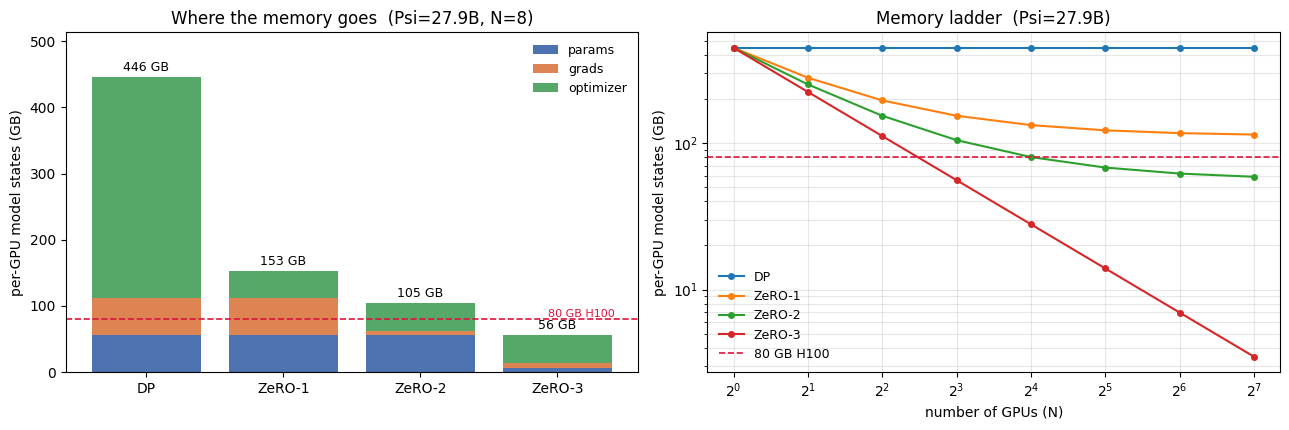

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plots.fig_memory_breakdown(27.9e9, 8, ax=axes[0])
plots.fig_memory_ladder(27.9e9, ax=axes[1])
plt.tight_layout(); plt.show()

The left panel is the argument for ZeRO in one picture: under DP the green
block (optimizer states) is almost the entire bar. That is why ZeRO-1 shards
it first.

The right panel is the one I find genuinely striking — **the DP line is
flat.** Adding GPUs to plain data parallelism moves your per-GPU memory not at
all. Only ZeRO-3 has slope −1. Everything between is partial.

## 4b · Compute — what changes, and what doesn't

This is the part I initially had wrong in my own head.

**ZeRO does not change FLOPs. At all.** Every stage runs identical arithmetic
on identical data — that is the *same* claim as the bit-identical weights
above. So "show how computation changes" cannot mean the arithmetic gets
cheaper.

What changes is **achieved throughput**, because communication sits in the
critical path and ZeRO-3 puts more of it there.

In [9]:
PSI, LAYERS, D, SEQ, TOK = 27.9e9, 64, 7168, 8192, 8192
f = {s: step_time(PSI, s, 8, H100_PROFILE, TOK, LAYERS, D, SEQ)['flops_per_gpu']
     for s in (0,1,2,3)}
print('FLOPs/GPU/step by stage:', {k: f'{v:.4g}' for k,v in f.items()})
print('all identical ->', len(set(f.values()))==1)

FLOPs/GPU/step by stage: {0: '1.741e+15', 1: '1.741e+15', 2: '1.741e+15', 3: '1.741e+15'}
all identical -> True


In [10]:
for N, nodes in ((8,1),(64,8)):
    print(f"H100, {N} GPUs, {nodes} node(s), 80% overlap")
    for s in (0,1,2,3):
        r = step_time(PSI, s, N, H100_PROFILE, TOK, LAYERS, D, SEQ,
                      nodes=nodes, overlap=0.8)
        fits = model_state_bytes(PSI, N, s).total <= 80e9
        print(f"   {STAGE_NAME[s]:14s} fits={str(fits):5s} "
              f"{r['tokens_per_second_per_gpu']:>8.0f} tok/s/GPU   "
              f"comms {r['comm_fraction_of_step']*100:>5.1f}% of step")
    print()

H100, 8 GPUs, 1 node(s), 80% overlap
   DP (no ZeRO)   fits=False     1864 tok/s/GPU   comms   1.0% of step
   ZeRO-1         fits=False     1864 tok/s/GPU   comms   1.0% of step
   ZeRO-2         fits=False     1864 tok/s/GPU   comms   1.0% of step
   ZeRO-3         fits=True      1802 tok/s/GPU   comms   4.3% of step

H100, 64 GPUs, 8 node(s), 80% overlap
   DP (no ZeRO)   fits=False     1692 tok/s/GPU   comms  10.1% of step
   ZeRO-1         fits=False     1692 tok/s/GPU   comms  10.1% of step
   ZeRO-2         fits=True      1692 tok/s/GPU   comms  10.1% of step
   ZeRO-3         fits=True      1251 tok/s/GPU   comms  33.5% of step



Two things I would not have predicted:

**ZeRO-3's cost is almost entirely about whether you crossed a node
boundary.** Inside one node it costs 3.3% throughput — basically free. Across
8 nodes, 26%. Same stage, same model. The 1.5× multiplier is constant; what
changes is the bandwidth it multiplies against.

**At 27.9B on 8× 80GB H100s, ZeRO-3 is the only stage that fits at all.** So
the throughput comparison against DP is hypothetical — you cannot run DP. That
reframed the question for me: often it isn't "which is faster", it's "which
ones are even available".

Below, a model small enough that every stage fits, so speed is comparable:

In [11]:
print(f"{'model':>7s} " + ' '.join(f"{STAGE_NAME[s]:>22s}" for s in (0,1,2,3)))
for psi_b in (1,3,7):
    psi = psi_b*1e9
    cells = []
    for s in (0,1,2,3):
        r = step_time(psi, s, 8, H100_PROFILE, 4096, 32, 4096, 4096,
                      nodes=1, overlap=0.8)
        gb = model_state_gb(psi, 8, s)
        ok = 'ok ' if model_state_bytes(psi,8,s).total <= 80e9 else 'OOM'
        cells.append(f"{gb:>6.1f}GB {ok} {r['tokens_per_second_per_gpu']:>7.0f}")
    print(f"{str(psi_b)+'B':>7s} " + ' '.join(f"{c:>22s}" for c in cells))

  model           DP (no ZeRO)                 ZeRO-1                 ZeRO-2                 ZeRO-3
     1B     16.0GB ok    31760      5.5GB ok    31760      3.8GB ok    31760      2.0GB ok    30474
     3B     48.0GB ok    16065     16.5GB ok    16065     11.2GB ok    16065      6.0GB ok    15098
     7B    112.0GB OOM    8080     38.5GB ok     8080     26.2GB ok     8080     14.0GB ok     7515


Read down a column: higher stage always costs throughput. Read across the 7B
row: higher stage is what makes it run at all. **Take the lowest stage that
fits.**

One caveat I want to be explicit about: my `compute_fraction_of_step` is
deliberately **not** called MFU. It is `compute_s/step_s`, and `compute_s` was
itself derived from the assumed TFLOP/s — so it's circular as an efficiency
metric and would read ~1.0 for a perfectly overlapped run with terrible
kernels. It measures only what fraction of the step is lost to exposed
communication. Real MFU needs measured wall-clock against a hardware ceiling.

## 5 · Does it match what real ZeRO does?

The session whiteboard gave six numbers but never stated the model size.
Solving the two clearly-stated N=8 values — `16Ψ = 447` and `2Ψ = 55` —
recovers Ψ. Then check whether that single constant predicts everything else.

In [12]:
transcript = {(8,0):447, (8,1):153, (8,3):55, (64,0):447, (64,1):117, (64,3):7}
PSI = 27.9e9
print(f"recovered Psi = {PSI/1e9:.1f} B parameters\n")
print(f"{'N':>4} {'stage':14s} {'computed':>10s} {'board':>8s} {'err':>7s}")
for N in (8,64):
    for s in (0,1,2,3):
        got = model_state_gb(PSI, N, s)
        exp = transcript.get((N,s))
        err = f"{abs(got-exp):.2f}" if exp else "  --"
        print(f"{N:>4} {STAGE_NAME[s]:14s} {got:>9.2f} {str(exp or '--'):>8s} {err:>7s}")

recovered Psi = 27.9 B parameters

   N stage            computed    board     err
   8 DP (no ZeRO)      446.40      447    0.60
   8 ZeRO-1            153.45      153    0.45
   8 ZeRO-2            104.62       --      --
   8 ZeRO-3             55.80       55    0.80
  64 DP (no ZeRO)      446.40      447    0.60
  64 ZeRO-1            116.83      117    0.17
  64 ZeRO-2             61.90       --      --
  64 ZeRO-3              6.97        7    0.03


Worst error 0.8 GB on a 447 GB figure. The **N=64 values were never used to
fit Ψ**, so they are a genuine out-of-sample check.

An independent confirmation from the *communication* side — the board
separately quoted "~120 GB per GPU per step", carried by NVLink in "around a
quarter second" and InfiniBand in "about 2.4 seconds":

In [13]:
dp_bytes = comm_volume_psi(0) * PSI * 2      # 2*Psi elements, fp16
print(f"DP all-reduce : {dp_bytes/1e9:6.1f} GB   (board said ~120)")
print(f"over NVLink   : {dp_bytes/(450*1e9):6.3f} s    (board said ~0.27)")
print(f"over InfiniBand:{dp_bytes/(45*1e9):6.3f} s    (board said ~2.4)")

DP all-reduce :  111.6 GB   (board said ~120)
over NVLink   :  0.248 s    (board said ~0.27)
over InfiniBand: 2.480 s    (board said ~2.4)


All three land within 10%, from a Ψ recovered purely off the memory table.

### Two corrections

- **ZeRO-2 at N=8 was never stated on the board.** It is 104.62 GB (`3.75Ψ`).
  My own first pass at explaining this session guessed "~95 GB" by
  interpolation — wrong, and the arithmetic says so.
- **ZeRO-2 at N=64 appears in the transcript as 72.** No ZeRO-2 form yields 72
  for the Ψ that fits the other five values; `2Ψ + 14Ψ/64` = 61.90 GB. Most
  likely a 62 → 72 transcription slip — flagging it rather than quietly
  substituting my own number.

## 6 · Bucket size

ZeRO-3 gathers weights bucket-by-bucket and frees each after use, so the
resident transient is one bucket rather than the whole model. This is the
trade-off drawn in the session.

In [14]:
psi = total_params(cfg)
print(f"{'bucket':>12s} {'peak/GPU':>12s} {'comm/step':>12s}")
for frac in (1,2,4,8,16,32):
    c = Cluster(world_size=32, gpus_per_node=8)
    e = ZeROEngine(3, cfg, c, Fabric(c, H100), lr=1e-2, seed=0,
                   bucket_elems=max(1, psi//frac))
    rs = [e.step(b) for b in steps[:3]]
    print(f"{'Psi/'+str(frac):>12s} {max(r.peak_bytes for r in rs):>12,} "
          f"{rs[-1].comm_bytes_per_gpu:>12,.0f}")

      bucket     peak/GPU    comm/step


       Psi/1      137,312      157,356


       Psi/2      110,240      157,356


       Psi/4       96,704      157,356


       Psi/8       89,936      157,356


      Psi/16       86,552      157,356


      Psi/32       84,860      157,356


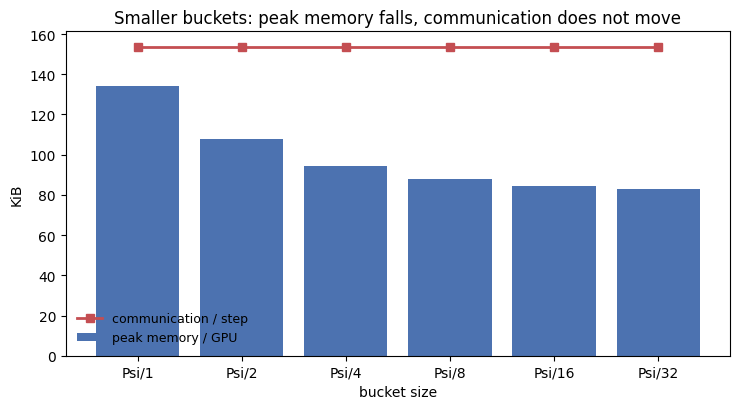

In [15]:
sweep = {}
for frac in (1,2,4,8,16,32):
    c = Cluster(world_size=32, gpus_per_node=8)
    e = ZeROEngine(3, cfg, c, Fabric(c, H100), lr=1e-2, seed=0,
                   bucket_elems=max(1, psi//frac))
    rs = [e.step(b) for b in steps[:3]]
    sweep[str(frac)] = {'peak_bytes_per_gpu': max(r.peak_bytes for r in rs),
                        'comm_bytes_per_gpu_per_step': rs[-1].comm_bytes_per_gpu}
fig, ax = plt.subplots(figsize=(7.5, 4.2))
plots.fig_bucket_tradeoff(sweep, ax=ax)
plt.tight_layout(); plt.show()

**Communication is completely flat; peak memory falls 1.62×.** The same bytes
cross the wire either way — only the resident transient shrinks. Smaller
buckets are close to free, which is why Rohan said to go as small as possible.

The floor is *latency*: past some point you are issuing many tiny transfers
and per-call overhead dominates. This simulator models bandwidth only, so it
shows the benefit continuing all the way down. That is a limitation, not a
finding.

## 7 · The economics — when does another node stop paying?

In [16]:
print(f"{'setup':34s} {'comm/step':>10s} {'step must exceed':>18s}")
for link, nm, bw_in, bw_out in ((H100,'H100',450,45), (B200,'B200',900,100)):
    for N, nodes in ((8,1),(16,2),(64,8)):
        bw = bw_in if nodes==1 else bw_out
        for s in (1,3):
            v = comm_volume_psi(s)*PSI*2*(N-1)/N
            secs = v/(bw*1e9)
            print(f"{nm+f', {N} GPU, {nodes} node, '+STAGE_NAME[s]:34s} "
                  f"{secs:>9.3f}s {secs*10:>17.2f}s")

setup                               comm/step   step must exceed
H100, 8 GPU, 1 node, ZeRO-1            0.217s              2.17s
H100, 8 GPU, 1 node, ZeRO-3            0.326s              3.25s
H100, 16 GPU, 2 node, ZeRO-1           2.325s             23.25s
H100, 16 GPU, 2 node, ZeRO-3           3.487s             34.88s
H100, 64 GPU, 8 node, ZeRO-1           2.441s             24.41s
H100, 64 GPU, 8 node, ZeRO-3           3.662s             36.62s
B200, 8 GPU, 1 node, ZeRO-1            0.108s              1.08s
B200, 8 GPU, 1 node, ZeRO-3            0.163s              1.63s
B200, 16 GPU, 2 node, ZeRO-1           1.046s             10.46s
B200, 16 GPU, 2 node, ZeRO-3           1.569s             15.69s
B200, 64 GPU, 8 node, ZeRO-1           1.099s             10.99s
B200, 64 GPU, 8 node, ZeRO-3           1.648s             16.48s


Crossing the **node boundary** is the expensive move — a 10× bandwidth cliff,
not a gradual slope. Going 8 → 16 GPUs costs more than going 16 → 64.

And the reason to pay it:

In [17]:
print(f"{'N':>5} " + ' '.join(f"{STAGE_NAME[s]:>12s}" for s in (0,1,2,3)))
for N in (8,32,64,128):
    row = ' '.join(f"{max_params(N,s,80e9)/1e9:>11.2f}B" for s in (0,1,2,3))
    print(f"{N:>5} {row}")

    N DP (no ZeRO)       ZeRO-1       ZeRO-2       ZeRO-3
    8        5.00B       14.55B       21.33B       40.00B
   32        5.00B       18.29B       32.82B      160.00B
   64        5.00B       19.10B       36.06B      320.00B
  128        5.00B       19.54B       37.93B      640.00B


Read the first column: under plain data parallelism the largest trainable
model is **5.00 B regardless of how many GPUs you add**. Adding GPUs to DP
buys throughput and exactly zero model size. That is the entire motivation for
ZeRO in one line.

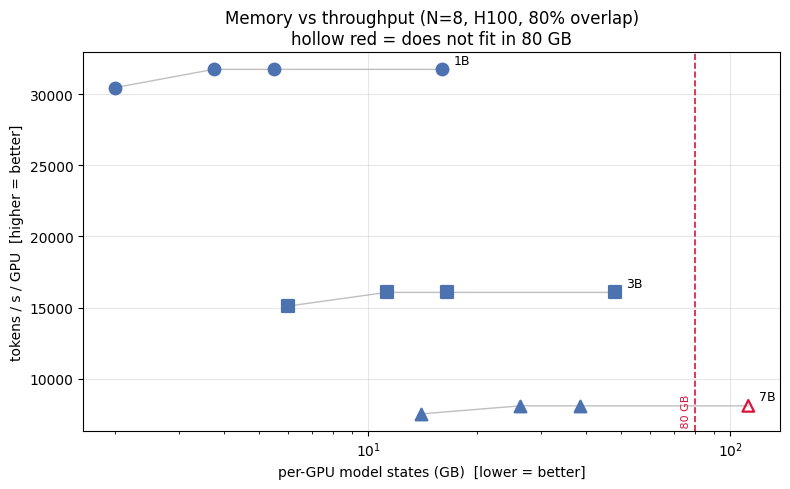

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
plots.fig_throughput_frontier(ax=ax)
plt.tight_layout(); plt.show()

Each grey line is one model size walking DP -> ZeRO-1 -> ZeRO-2 -> ZeRO-3.
Every step moves left (less memory) and slightly down (less throughput). The
hollow red markers are configurations that do not fit in 80 GB at all — note
that for 7B, DP is hollow, so the "DP is fastest" comparison is meaningless
there. You cannot run it.

## 7b · Three things I got wrong

Including these because the assignment asks whether *I* understood this, and
honestly I understood it by getting it wrong first.

**(a) I had ZeRO-1 doing a full all-reduce.** That made it look like it cost
3Ψ. Wrong — a ZeRO-1 rank only updates its own slice, so reduce-scatter gives
it exactly what it needs. ZeRO-1 and ZeRO-2 communicate **identically**. The
consequence: **ZeRO-2 strictly dominates ZeRO-1** — better memory, same wire
cost, same math. There is no configuration where ZeRO-1 is the right answer.
I didn't know that before building this, and it isn't obvious from the
lecture table where they look like two rungs with a trade-off between them.

**(b) My ZeRO-3 gathered weights only once**, holding them across forward and
backward. Wrong in a way that mattered: ZeRO-3 frees each bucket right after
the forward uses it — *that freeing is the entire memory saving* — so the
backward has to gather again. Two gathers + one reduce-scatter is where 3Ψ
comes from. My version was claiming ZeRO-3's memory while paying ZeRO-2's
communication.

**(c) I guessed instead of deriving.** Explaining ZeRO-2 at N=8 before building
anything, I said "~95 GB" by eyeballing between 153 and 55. It is **104.62 GB**.
Interpolating linearly on a curve of the form `a + b/N` is just wrong.

The first two were caught by a test failing, not by me re-reading the code.
That is the argument for writing the invariant tests first.

## 8 · Pros and cons

**ZeRO-1** — 3.66× memory for free (identical comms to DP). Superseded by
ZeRO-2; no reason to stop here.

**ZeRO-2** — 6.56×, still zero extra communication. **The sensible default.**

**ZeRO-3** — reduction equal to world size, and the only stage where adding
GPUs increases trainable model size. Costs 1.5× communication, and every
forward *and* backward now depends on the network, so a slow interconnect
shows up in every step. Use when the model does not fit under ZeRO-2.

**Decision rule: take the lowest stage that fits.** Memory is the binding
constraint, not compute. You are not making the GPU think faster — you are
making a bigger model fit inside it.

### For the V5 run

The open questions from the session, with what this simulation says:

- *Stage?* Start at ZeRO-2 — free relative to ZeRO-1. Move to ZeRO-3 only when
  the target size genuinely does not fit, because the 1.5× lands on every step.
- *How many GPUs per node?* Fill nodes before adding them. The node boundary is
  a 10× cliff.
- *Bucket size?* Small. Volume is unchanged and peak memory drops — bounded
  below only by per-call latency, which this model does not capture.
- *FP8?* Orthogonal to all of the above. It shrinks the 2Ψ fp16 terms but not
  the 12Ψ optimizer states, so the *sharding* argument is unchanged.

## 9 · Limitations

See README §8 for the full list. The ones that matter most for reading these
numbers: memory is **modelled rather than measured** (compute is float64 NumPy;
the ledger accounts fp16/fp32 as a real run would store them — ratios are
exact, absolute bytes are hypothetical); there is **no latency term**, so the
bucket sweep overstates the benefit of very small buckets; and comms are
charged as **fully serialised**, where real DeepSpeed/FSDP overlap them.